# 23CSE301 Machine Learning – Capstone: Clustering Track
**Dataset:** Healthcare Insurance Claims (`healthcare_fraud_detection.csv`, 18,764 claims × 20 columns)
**Algorithms:** K-Means Clustering and Agglomerative Hierarchical Clustering
**Metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index
**Visualisations:** Elbow curve, Dendrogram, PCA 2-D scatter, t-SNE

### Problem statement
Insurance claims arrive without any "behaviour group" label. Our goal is to **discover natural groups of claims** (e.g. high-value / fast-submitted / high-volume-provider claims) using only unsupervised learning, and do any of these groups line up with fraud risk?

#note
Clustering is **unsupervised**: `Is_Fraud` is **never used when fitting**. It is used only *after* clustering (Section 10) to interpret / validate the groups.

### Notebook map
1. Setup → 2. Dataset audit → 3. EDA → 4. Cleaning & feature engineering → 5. Feature selection & scaling → 6. K-Means → 7. Hierarchical → 8. Comparison → 9. PCA & t-SNE → 10. Profiling & fraud validation → 11. Stability → 12. Conclusions

## 1. Setup

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')   # colour-blind friendly palette
PALETTE = sns.color_palette('colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})

# Works from repo root (data/...) or from the notebooks/ folder (../data/...) or the current folder
for p in ['data/healthcare_fraud_detection.csv', '../data/healthcare_fraud_detection.csv', 'healthcare_fraud_detection.csv']:
    if Path(p).exists():
        DATA_PATH = p; break
print('Using data file:', DATA_PATH)

Using data file: healthcare_fraud_detection.csv


## 2. Dataset loading & audit

In [ ]:
df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
display(df_raw.head())
print('\nData types:'); display(df_raw.dtypes.to_frame('dtype').T)
audit = pd.DataFrame({'missing': df_raw.isna().sum(), 'missing_%': (df_raw.isna().mean()*100).round(2), 'n_unique': df_raw.nunique()})
print('\nMissing values & cardinality:'); display(audit)
print('Duplicate rows (all columns):', df_raw.duplicated().sum())
print('Duplicate rows (ignoring Claim_ID):', df_raw.drop(columns='Claim_ID').duplicated().sum())
print('\nReference label distribution (NOT used for fitting):')
display(df_raw['Is_Fraud'].value_counts().to_frame('count').assign(pct=lambda d: (d['count']/len(df_raw)*100).round(2)))
print('Claims where Approved_Amount > Claim_Amount:', (df_raw.Approved_Amount > df_raw.Claim_Amount).sum())

Shape: (18764, 20)


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0



Data types:


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
dtype,str,str,int64,str,str,int64,float64,float64,str,str,int64,int64,str,str,str,int64,int64,str,int64,float64



Missing values & cardinality:


,missing,missing_%,n_unique
Provider_ID,0,0.00,5861
Claim_ID,0,0.00,18764
Patient_Age,0,0.00,95
Patient_Gender,0,0.00,2
Diagnosis_Code,0,0.00,10
Procedure_Code,0,0.00,9
Claim_Amount,0,0.00,16478
Approved_Amount,0,0.00,16655
Insurance_Type,600,3.20,4
Claim_Submission_Date,0,0.00,1482


Duplicate rows (all columns): 0
Duplicate rows (ignoring Claim_ID): 0

Reference label distribution (NOT used for fitting):


,count,pct
Is_Fraud,,
0,17139,91.34
1,1625,8.66


Claims where Approved_Amount > Claim_Amount: 968


**Insight (audit):** 18,764 claims × 20 columns, no duplicates. Missing values sit in three columns only: `Insurance_Type` (600, 3.2%), `Provider_Specialty` (663, 3.5%) and `Prior_Visits_12m` (828, 4.4%) – all small, so imputation is safe. The reference label is imbalanced (8.7% fraud, 1,625 claims) – irrelevant for fitting but important when validating later. Two data-quality oddities: 968 claims have `Approved_Amount` > `Claim_Amount`, and `Length_of_Stay` > 0 appears for ~80% of *Outpatient* visits, so the data is clearly synthetic/simulated rather than real hospital data.

## 3. Exploratory Data Analysis

### 3.1 Numeric feature distributions

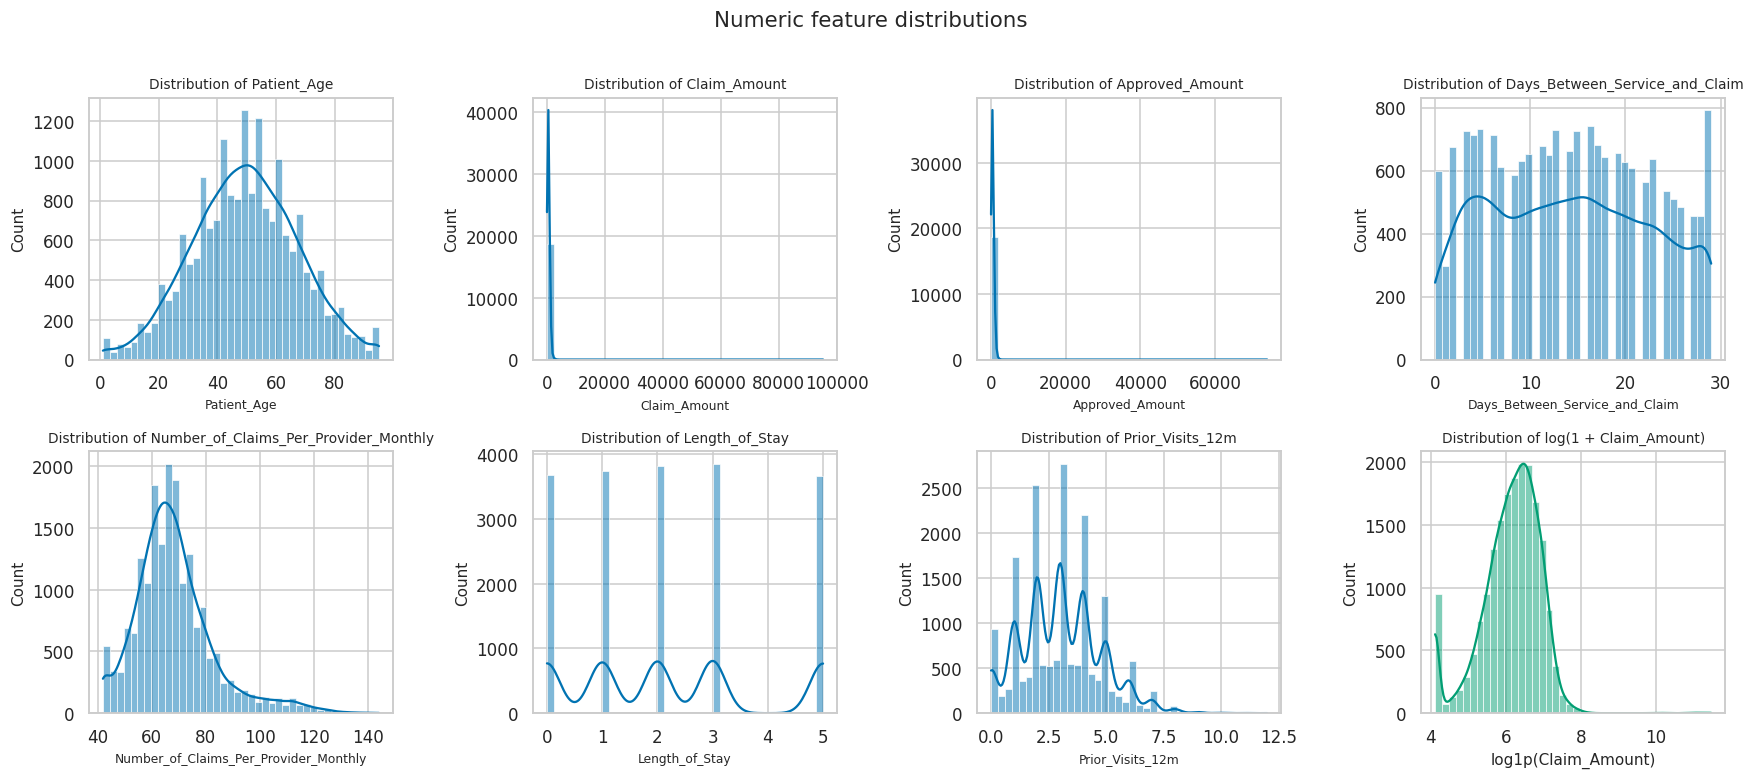

,count,mean,std,min,25%,50%,75%,max
Patient_Age,18764.0,49.50,17.92,1.0,37.00,50.00,62.00,95.00
Claim_Amount,18764.0,633.28,1910.74,60.0,301.77,508.49,788.93,95251.00
Approved_Amount,18764.0,530.63,1583.91,50.0,252.78,424.67,661.76,73867.64
Days_Between_Service_and_Claim,18764.0,14.21,8.39,0.0,7.00,14.00,21.00,29.00
Number_of_Claims_Per_Provider_Monthly,18764.0,68.44,14.79,42.0,59.00,66.00,75.00,144.00
Length_of_Stay,18764.0,2.20,1.70,0.0,1.00,2.00,3.00,5.00
Prior_Visits_12m,17936.0,3.03,1.69,0.0,2.00,3.00,4.00,12.00


In [ ]:
num_cols = ['Patient_Age','Claim_Amount','Approved_Amount','Days_Between_Service_and_Claim',
            'Number_of_Claims_Per_Provider_Monthly','Length_of_Stay','Prior_Visits_12m']
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    sns.histplot(df_raw[c].dropna(), bins=40, kde=True, ax=ax, color=PALETTE[0])
    ax.set_title(f'Distribution of {c}', fontsize=9); ax.set_xlabel(c, fontsize=8); ax.set_ylabel('Count')
sns.histplot(np.log1p(df_raw['Claim_Amount']), bins=40, kde=True, ax=axes[7], color=PALETTE[2])
axes[7].set_title('Distribution of log(1 + Claim_Amount)', fontsize=9); axes[7].set_xlabel('log1p(Claim_Amount)'); axes[7].set_ylabel('Count')
plt.suptitle('Numeric feature distributions', y=1.01, fontsize=14); plt.tight_layout(); plt.show()
display(df_raw[num_cols].describe().T.round(2))

**Insight (distributions):** `Claim_Amount` is extremely right-skewed (median ≈ 508, max 95,251, skewness ≈ 38) → a log transform is needed before any distance-based method. After `log1p` it is close to bell-shaped. `Days_Between_Service_and_Claim` is roughly uniform over 0–29 days, `Patient_Age` is symmetric (mean ≈ 49.5), and `Number_of_Claims_Per_Provider_Monthly` is mildly right-skewed with a floor of 42 and a tail to 144. `Length_of_Stay` and `Prior_Visits_12m` are small discrete counts.

### 3.2 Categorical features

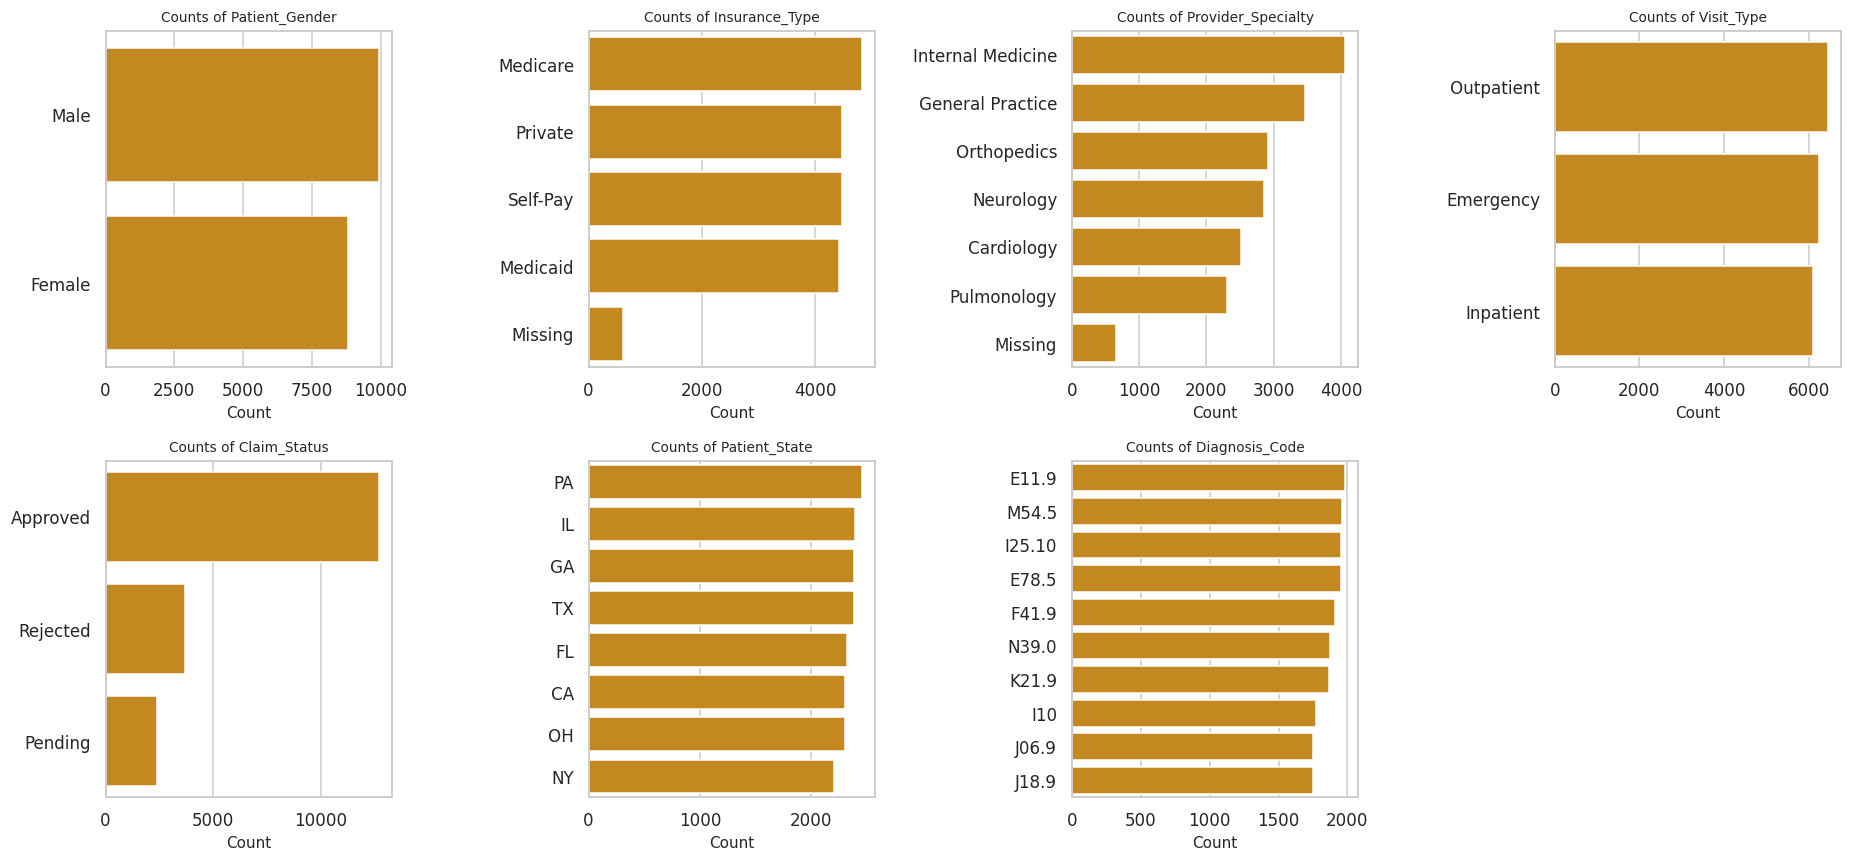

In [ ]:
cat_cols = ['Patient_Gender','Insurance_Type','Provider_Specialty','Visit_Type','Claim_Status','Patient_State','Diagnosis_Code']
fig, axes = plt.subplots(2, 4, figsize=(17, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    order = df_raw[c].fillna('Missing').value_counts().index
    sns.countplot(y=df_raw[c].fillna('Missing'), order=order, ax=ax, color=PALETTE[1])
    ax.set_title(f'Counts of {c}', fontsize=9); ax.set_xlabel('Count'); ax.set_ylabel('')
axes[7].axis('off'); plt.tight_layout(); plt.show()

**Insight (categoricals):** Every categorical variable is almost perfectly balanced – visit types ≈ ⅓ each, the four insurance types ≈ 24% each, eight states ≈ 12–13% each, ten diagnosis codes ≈ 10% each. Only `Claim_Status` is uneven (≈ 68% Approved, 20% Rejected, 13% Pending). Balanced categories with no dominant level suggest they carry little structure on their own, so they are used to **profile** clusters later rather than to build them.

### 3.3 Correlation heatmap

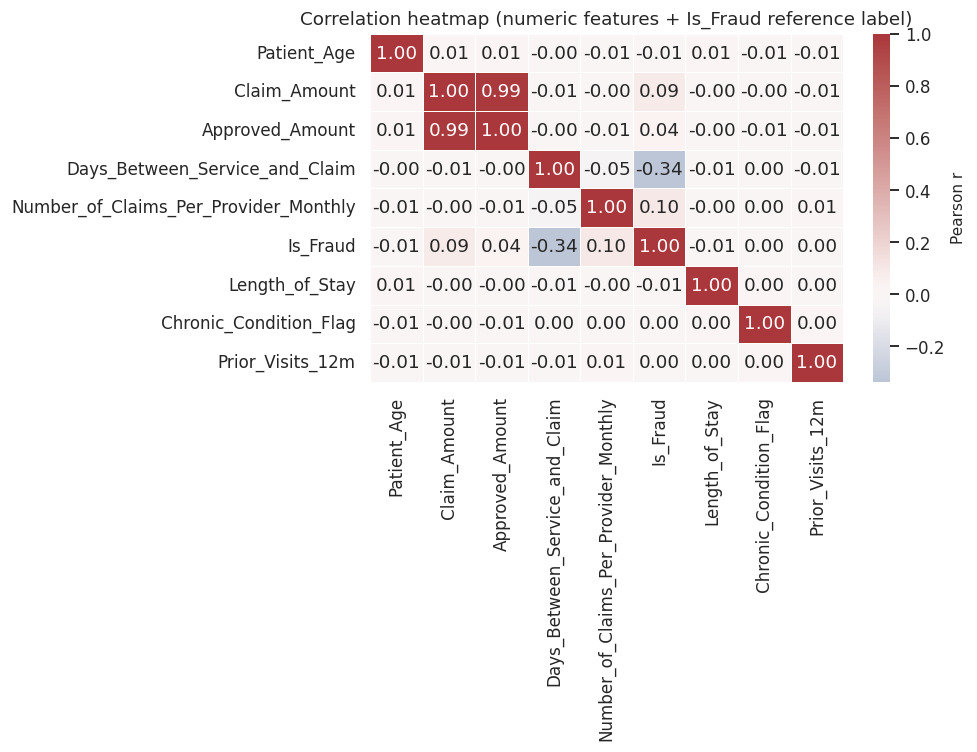

In [ ]:
corr = df_raw.select_dtypes('number').drop(columns=['Procedure_Code']).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, linewidths=.5, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation heatmap (numeric features + Is_Fraud reference label)'); plt.tight_layout(); plt.show()

**Insight (correlation):** Two things stand out. (1) `Claim_Amount` and `Approved_Amount` are 0.99 correlated – redundant, so we replace the pair with an approval ratio. (2) Apart from that, the numeric features are almost completely uncorrelated (|r| ≈ 0.00–0.05) – a sign of simulated data and a warning that **natural cluster structure will be weak**. Against the reference label, `Days_Between_Service_and_Claim` (r = −0.34), `Number_of_Claims_Per_Provider_Monthly` (0.10) and `Claim_Amount` (0.09) are the only features with any link to fraud.

### 3.4 Relationships that matter for clustering

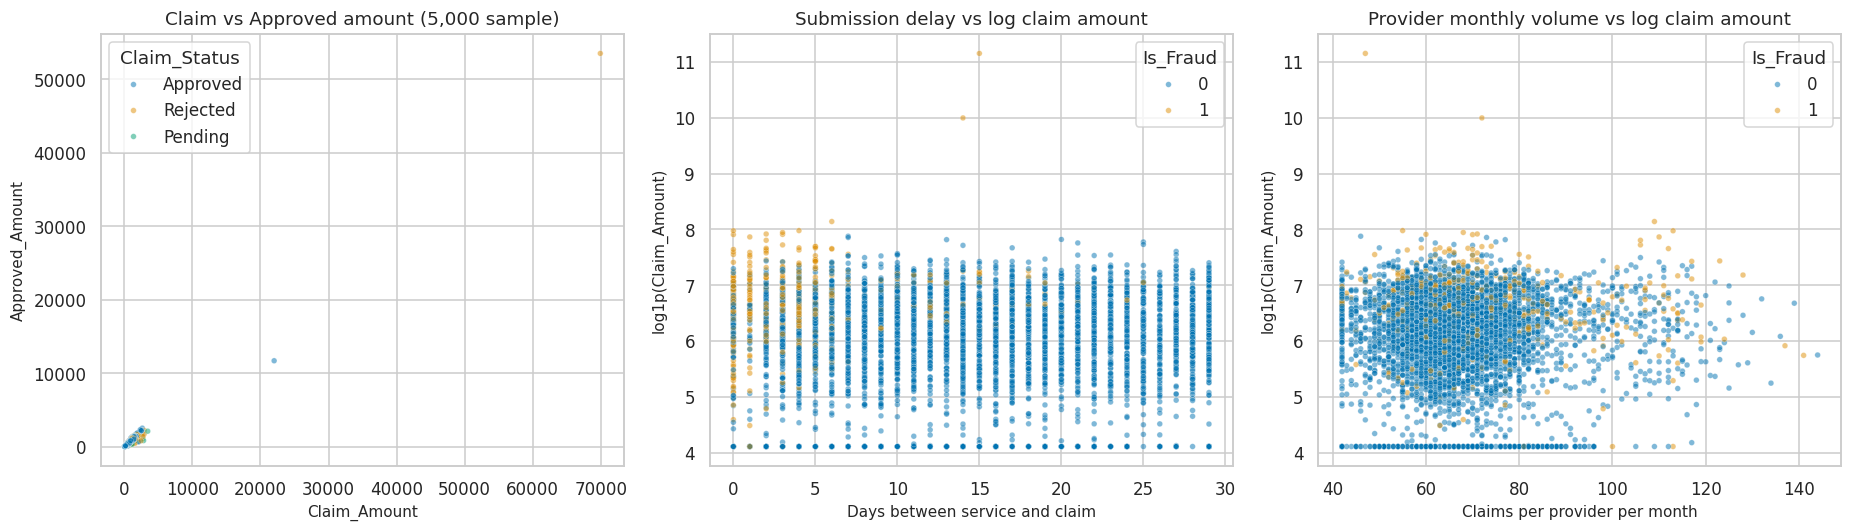

Mean of key features split by the reference label (for EDA only):


Claim_Amount        Approved_Amount         \
                 mean median            mean median   
Is_Fraud                                              
0               583.2  484.6           511.6  420.4   
1              1161.8  788.3           730.9  475.1   

         Days_Between_Service_and_Claim         \
                                   mean median   
Is_Fraud                                         
0                                  15.1   15.0   
1                                   5.1    4.0   

         Number_of_Claims_Per_Provider_Monthly         
                                          mean median  
Is_Fraud                                               
0                                         68.0   66.0  
1                                         73.2   69.0

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
s = df_raw.sample(5000, random_state=RANDOM_STATE)
sns.scatterplot(data=s, x='Claim_Amount', y='Approved_Amount', hue='Claim_Status', alpha=.5, s=14, ax=axes[0])
axes[0].set_title('Claim vs Approved amount (5,000 sample)'); axes[0].set_xlabel('Claim_Amount'); axes[0].set_ylabel('Approved_Amount')
sns.scatterplot(data=s, x='Days_Between_Service_and_Claim', y=np.log1p(s['Claim_Amount']), hue='Is_Fraud', palette='colorblind', alpha=.5, s=14, ax=axes[1])
axes[1].set_title('Submission delay vs log claim amount'); axes[1].set_ylabel('log1p(Claim_Amount)'); axes[1].set_xlabel('Days between service and claim')
sns.scatterplot(data=s, x='Number_of_Claims_Per_Provider_Monthly', y=np.log1p(s['Claim_Amount']), hue='Is_Fraud', palette='colorblind', alpha=.5, s=14, ax=axes[2])
axes[2].set_title('Provider monthly volume vs log claim amount'); axes[2].set_ylabel('log1p(Claim_Amount)'); axes[2].set_xlabel('Claims per provider per month')
plt.tight_layout(); plt.show()

print('Mean of key features split by the reference label (for EDA only):')
display(df_raw.groupby('Is_Fraud')[['Claim_Amount','Approved_Amount','Days_Between_Service_and_Claim','Number_of_Claims_Per_Provider_Monthly']].agg(['mean','median']).round(1))

**Insight (relationships):** Claimed and approved amounts lie on a tight diagonal band (approval is ≈ 85% of the claim on average). Fraud-flagged claims (reference label, EDA only) are submitted much faster – mean 5.1 days vs 15.1 days for non-fraud – and are larger (mean 1,162 vs 583) and come from busier providers (73 vs 68 claims/month). So three behavioural dimensions – **submission delay, claim size, provider volume** – plus the approval ratio are the natural candidates for clustering.

### 3.5 Outlier check (IQR rule)

In [ ]:
rows = []
for c in ['Claim_Amount','Approved_Amount','Number_of_Claims_Per_Provider_Monthly','Patient_Age','Prior_Visits_12m']:
    q1, q3 = df_raw[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df_raw[c] < lo) | (df_raw[c] > hi)).sum()
    rows.append([c, round(lo,1), round(hi,1), n, round(n/len(df_raw)*100,2)])
display(pd.DataFrame(rows, columns=['feature','lower_fence','upper_fence','n_outliers','outlier_%']))
big = df_raw[df_raw.Claim_Amount > 10000]
print(f'Claims above 10,000: {len(big)}  | fraud rate among them: {big.Is_Fraud.mean():.1%}  (overall: {df_raw.Is_Fraud.mean():.1%})')

,feature,lower_fence,upper_fence,n_outliers,outlier_%
0,Claim_Amount,-429.0,1519.7,439,2.34
1,Approved_Amount,-360.7,1275.2,461,2.46
2,Number_of_Claims_Per_Provider_Monthly,35.0,99.0,887,4.73
3,Patient_Age,-0.5,99.5,0,0.00
4,Prior_Visits_12m,-1.0,7.0,191,1.02


Claims above 10,000: 15  | fraud rate among them: 46.7%  (overall: 8.7%)


**Insight (outliers):** About 2.3% of claim amounts and 4.7% of provider monthly volumes fall outside the IQR fences. Rather than deleting them we keep them: only 15 claims exceed 10,000 but **46.7% of those are fraud-flagged** (vs 8.7% overall), so the extreme claims are informative. The log transform tames their influence on distances without discarding them. Age has no outliers.

## 4. Data cleaning & feature engineering

In [ ]:
df = df_raw.copy()

# (a) Drop identifiers - they carry no behavioural information and would add noise
df = df.drop(columns=['Provider_ID', 'Claim_ID'])

# (b) Duplicates
n_dup = df.duplicated().sum(); df = df.drop_duplicates(); print('Duplicates removed:', n_dup)

# (c) Missing values - justified strategies
df['Insurance_Type']     = df['Insurance_Type'].fillna('Unknown')       # categorical: keep as its own level, avoids inventing a payer
df['Provider_Specialty'] = df['Provider_Specialty'].fillna('Unknown')
df['Prior_Visits_12m']   = df['Prior_Visits_12m'].fillna(df['Prior_Visits_12m'].median())  # small right-skewed count -> median
print('Remaining missing values:', int(df.isna().sum().sum()))

# (d) Feature engineering
# Log transform: Claim_Amount is extremely right-skewed (max ~95k vs median ~500); distance-based methods would be dominated by a few giant claims.
df['Log_Claim_Amount'] = np.log1p(df['Claim_Amount'])
# Approval ratio: scale-free measure of how much of the claim the insurer accepted; ~0.85 is normal, very low/high values are unusual.
df['Approval_Ratio'] = df['Approved_Amount'] / df['Claim_Amount']
print('\nEngineered features:'); display(df[['Log_Claim_Amount','Approval_Ratio']].describe().T.round(3))

Duplicates removed: 0
Remaining missing values: 0

Engineered features:


,count,mean,std,min,25%,50%,75%,max
Log_Claim_Amount,18764.0,6.128,0.783,4.111,5.713,6.233,6.672,11.464
Approval_Ratio,18764.0,0.851,0.120,0.300,0.790,0.859,0.932,1.263


**Why these engineered features?**
- `Log_Claim_Amount` – compresses a heavy right tail so that outliers do not dominate Euclidean distance, **without deleting** the large claims (they turn out to be informative – see Section 3.5).
- `Approval_Ratio` – `Claim_Amount` and `Approved_Amount` are 0.99 correlated (redundant). Replacing the pair with their ratio keeps the *new* information (how generous / strict the approval was) and removes the duplicate.

## 5. Feature selection & scaling for clustering

Distance-based clustering treats every feature equally, so **irrelevant features dilute cluster structure**. Several columns (`Patient_Age`, `Length_of_Stay`, `Prior_Visits_12m`) have ≈ 0 correlation with every other variable (Section 3.3). We test this empirically with a **feature-set ablation** using K-Means (k = 2…6) before committing to a feature set.

In [ ]:
def quick_scores(cols, ks=range(2, 7)):
    X = StandardScaler().fit_transform(df[cols])
    rng_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 5000, replace=False)
    out = []
    for k in ks:
        lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
        out.append(silhouette_score(X[rng_idx], lab[rng_idx]))
    return np.mean(out), max(out)

all_numeric = ['Patient_Age','Log_Claim_Amount','Approval_Ratio','Days_Between_Service_and_Claim',
               'Number_of_Claims_Per_Provider_Monthly','Length_of_Stay','Prior_Visits_12m']
core = ['Log_Claim_Amount','Approval_Ratio','Days_Between_Service_and_Claim','Number_of_Claims_Per_Provider_Monthly']
abl = pd.DataFrame({'feature_set': ['All 7 numeric (incl. noise features)', 'Core 4 behavioural features'],
                    'n_features': [len(all_numeric), len(core)]})
res = [quick_scores(all_numeric), quick_scores(core)]
abl['mean_silhouette_k2-6'] = [round(r[0], 3) for r in res]; abl['best_silhouette'] = [round(r[1], 3) for r in res]
display(abl)

,feature_set,n_features,mean_silhouette_k2-6,best_silhouette
0,All 7 numeric (incl. noise features),7,0.115,0.120
1,Core 4 behavioural features,4,0.213,0.233


**Insight (feature selection):** Dropping the three noise features (`Patient_Age`, `Length_of_Stay`, `Prior_Visits_12m`) almost **doubles** the cluster quality – mean silhouette 0.115 → 0.213, best silhouette 0.120 → 0.233. Irrelevant, uniformly random dimensions blur the distances between claims. The final clustering uses 4 features: `Log_Claim_Amount`, `Approval_Ratio`, `Days_Between_Service_and_Claim`, `Number_of_Claims_Per_Provider_Monthly`. Categoricals are excluded from fitting (balanced, uninformative, and one-hot columns would add more noise dimensions) and used only for profiling.

In [ ]:
FEATURES = core
X = df[FEATURES].copy()

# Scaling: StandardScaler (K-Means and Ward linkage both use Euclidean distance, so features must be on the same scale).
# Clustering has no train/test split; the scaler is fitted on the data that is clustered.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled matrix:', X_scaled.shape, '| mean ~', X_scaled.mean(0).round(3), '| std ~', X_scaled.std(0).round(3))

# Hierarchical clustering needs an n x n distance matrix (18,764^2 ~ 2.8 GB) -> use one fixed random sample for all
# like-for-like comparisons and for the dendrogram.
SAMPLE_N = 5000
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), SAMPLE_N, replace=False)
X_s = X_scaled[idx]
print('Sample for hierarchical / comparison table:', X_s.shape)

def evaluate(Xm, labels):
    # All three required internal metrics. Silhouette on 18k points is O(n^2) so it uses a 5,000 sample when n is large.
    sil = silhouette_score(Xm, labels, sample_size=min(5000, len(Xm)), random_state=RANDOM_STATE) if len(Xm) > 5000 else silhouette_score(Xm, labels)
    return {'Silhouette (↑)': sil, 'Davies-Bouldin (↓)': davies_bouldin_score(Xm, labels),
            'Calinski-Harabasz (↑)': calinski_harabasz_score(Xm, labels)}

Scaled matrix: (18764, 4) | mean ~ [0. 0. 0. 0.] | std ~ [1. 1. 1. 1.]
Sample for hierarchical / comparison table: (5000, 4)


## 6. K-Means clustering

### 6.1 Choosing k – Elbow curve + supporting metrics

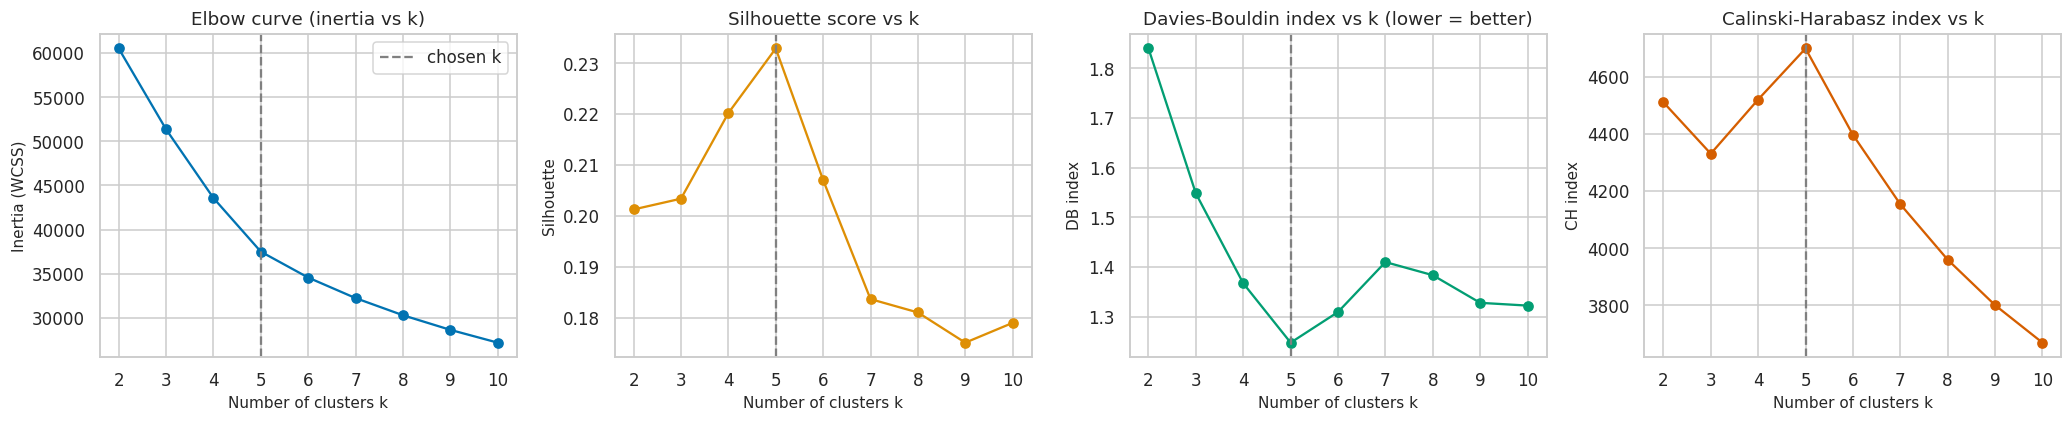

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Inertia
k,,,,
2,0.201,1.840,4510.711,60508.926
3,0.203,1.548,4330.573,51350.148
4,0.220,1.367,4520.239,43565.036
5,0.233,1.248,4698.950,37491.270
6,0.207,1.310,4396.663,34557.139
7,0.184,1.410,4153.694,32231.239
8,0.181,1.384,3959.543,30292.099
9,0.175,1.328,3800.451,28635.762
10,0.179,1.322,3669.101,27186.506


In [ ]:
ks = range(2, 11); rows = []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    m = evaluate(X_scaled, km.labels_); m.update({'k': k, 'Inertia': km.inertia_}); rows.append(m)
kdf = pd.DataFrame(rows).set_index('k')

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].plot(kdf.index, kdf['Inertia'], 'o-', color=PALETTE[0]); axes[0].set_title('Elbow curve (inertia vs k)'); axes[0].set_ylabel('Inertia (WCSS)')
axes[1].plot(kdf.index, kdf['Silhouette (↑)'], 'o-', color=PALETTE[1]); axes[1].set_title('Silhouette score vs k'); axes[1].set_ylabel('Silhouette')
axes[2].plot(kdf.index, kdf['Davies-Bouldin (↓)'], 'o-', color=PALETTE[2]); axes[2].set_title('Davies-Bouldin index vs k (lower = better)'); axes[2].set_ylabel('DB index')
axes[3].plot(kdf.index, kdf['Calinski-Harabasz (↑)'], 'o-', color=PALETTE[3]); axes[3].set_title('Calinski-Harabasz index vs k'); axes[3].set_ylabel('CH index')
for a in axes: a.set_xlabel('Number of clusters k'); a.set_xticks(list(ks))
if 5 in ks:
    for a in axes: a.axvline(5, ls='--', color='grey', label='chosen k');
    axes[0].legend()
plt.tight_layout(); plt.show()
display(kdf.round(3))

**Insight (choosing k):** The elbow curve falls smoothly with no sharp bend, so the elbow alone is not decisive. The other three metrics, however, **all agree on k = 5**: silhouette peaks (0.233), Davies-Bouldin is lowest (1.248) and Calinski-Harabasz is highest (4,699). Beyond k = 5 every quality metric deteriorates. We therefore choose **k = 5**.

### 6.2 Final K-Means model

In [ ]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
df['KMeans_Cluster'] = kmeans.labels_
km_full = evaluate(X_scaled, kmeans.labels_)
print(f'K-Means (k={K}) on all {len(X_scaled):,} claims'); display(pd.Series(km_full).round(3).to_frame('score').T)
display(df['KMeans_Cluster'].value_counts().sort_index().to_frame('claims').assign(pct=lambda d: (d.claims/len(df)*100).round(1)))

K-Means (k=5) on all 18,764 claims


,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
score,0.233,1.248,4698.951


,claims,pct
KMeans_Cluster,,
0,1480,7.9
1,6152,32.8
2,2946,15.7
3,6314,33.6
4,1872,10.0


**Insight (K-Means):** With k = 5 the clusters have sizes of 7.9%, 32.8%, 15.7%, 33.6% and 10.0% – no degenerate clusters. A silhouette of 0.23 is considered *weak-to-moderate* (0.5+ would be strong separation); this is expected given the near-zero correlations found in EDA. The clusters are best read as soft behavioural *segments*, not sharply separated groups.

## 7. Agglomerative hierarchical clustering

### 7.1 Dendrogram (Ward linkage, 5,000-claim sample)

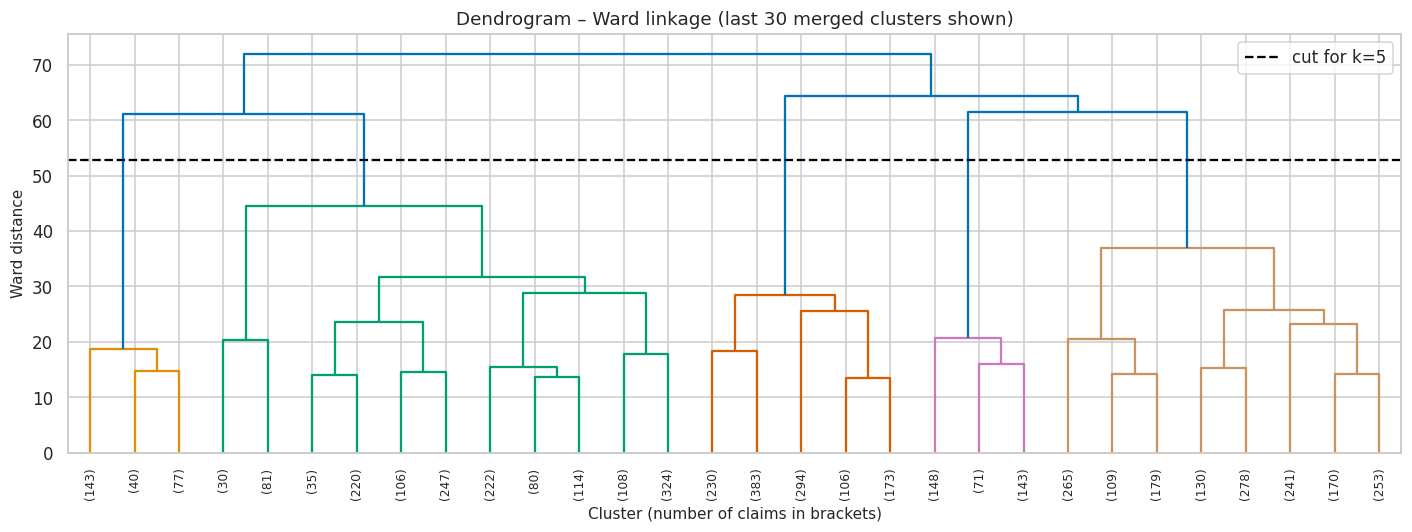

Last 10 merge heights (large jumps = natural cut points): [25.7 28.5 28.8 31.6 37.  44.5 61.2 61.5 64.4 72. ]


In [ ]:
Z = linkage(X_s, method='ward')
# height at which the tree is cut to give K clusters
cut_height = (Z[-K, 2] + Z[-K+1, 2]) / 2
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8, color_threshold=cut_height)
plt.axhline(cut_height, ls='--', color='black', label=f'cut for k={K}')
plt.title('Dendrogram – Ward linkage (last 30 merged clusters shown)'); plt.xlabel('Cluster (number of claims in brackets)'); plt.ylabel('Ward distance')
plt.legend(); plt.tight_layout(); plt.show()
print('Last 10 merge heights (large jumps = natural cut points):', np.round(Z[-10:, 2], 1))

**Insight (dendrogram):** The tree shows no single dramatic gap, which again indicates continuous rather than sharply separated structure. The last merge heights (…37.0, 44.5, 61.2, 61.5, 64.4, 72.0) show a visible jump from 44.5 to 61.2, so cutting at ≈ 53 yields **5 clusters** – the same k chosen by K-Means, which allows a fair comparison.

### 7.2 Comparing linkage strategies (same k, same sample)

In [ ]:
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X_s)
    m = evaluate(X_s, lab); m['linkage'] = link; m['smallest cluster (claims)'] = int(np.bincount(lab).min()); rows.append(m)
link_df = pd.DataFrame(rows).set_index('linkage'); display(link_df.round(3))

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),smallest cluster (claims)
linkage,,,,
ward,0.166,1.433,938.468,260
complete,0.117,1.773,404.705,2
average,0.290,0.922,299.734,2
single,0.482,0.323,11.540,1


**Insight (linkage comparison):** *Single*, *average* and *complete* linkage produce **degenerate partitions** – their smallest cluster has only 1–2 claims (outliers are isolated and everything else is lumped together). Single linkage's "excellent" silhouette (0.48) and Davies-Bouldin (0.32) are therefore misleading – note its Calinski-Harabasz collapses to 11.5. **Ward** is the only linkage that returns balanced clusters (smallest = 260 claims) and has the best CH (938), so Ward is used. Lesson for the viva: a high silhouette alone does not prove a good clustering – always check cluster sizes.

### 7.3 Final hierarchical model (Ward)

In [ ]:
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X_s)
agg_labels = agg.labels_                       # labels for the 5,000-claim sample
df_s = df.iloc[idx].copy(); df_s['Agglo_Cluster'] = agg_labels; df_s['KMeans_Cluster'] = kmeans.labels_[idx]
display(df_s['Agglo_Cluster'].value_counts().sort_index().to_frame('claims').assign(pct=lambda d: (d.claims/len(df_s)*100).round(1)))

,claims,pct
Agglo_Cluster,,
0,1567,31.3
1,1625,32.5
2,1186,23.7
3,362,7.2
4,260,5.2


## 8. Algorithm comparison

In [ ]:
# Like-for-like: both algorithms scored on the SAME 5,000 claims
cmp = pd.DataFrame({
    f'K-Means (k={K}) – 5k sample':      evaluate(X_s, kmeans.labels_[idx]),
    f'Agglomerative Ward (k={K}) – 5k sample': evaluate(X_s, agg_labels),
    f'K-Means (k={K}) – all 18,764 claims':   km_full}).T
display(cmp.round(3))
agreement = adjusted_rand_score(kmeans.labels_[idx], agg_labels)
print(f'Agreement between K-Means and Hierarchical partitions (Adjusted Rand Index): {agreement:.3f}')

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
K-Means (k=5) – 5k sample,0.233,1.238,1263.043
Agglomerative Ward (k=5) – 5k sample,0.166,1.433,938.468
"K-Means (k=5) – all 18,764 claims",0.233,1.248,4698.951


Agreement between K-Means and Hierarchical partitions (Adjusted Rand Index): 0.275


**Insight (comparison):** On the same 5,000 claims, **K-Means wins on all three metrics** (silhouette 0.233 vs 0.166, Davies-Bouldin 1.238 vs 1.433 – lower is better, Calinski-Harabasz 1,263 vs 938). K-Means' compact, roughly spherical centroids suit this blob-like data, whereas Ward's merges are greedy and cannot revisit early mistakes. The partitions only partly agree (ARI = 0.275), confirming that without clear natural groups the choice of algorithm changes the result. *Note:* Calinski-Harabasz grows with the number of points, so the full-data row (4,699) is **not** comparable with the 5k-sample rows – compare like with like.

## 9. Cluster visualisation

### 9.1 PCA – 2 principal components

Explained variance ratio: [0.315 0.247] | total: 0.561


,PC1,PC2
Log_Claim_Amount,-0.445,-0.574
Approval_Ratio,0.646,0.090
Days_Between_Service_and_Claim,0.537,-0.117
Number_of_Claims_Per_Provider_Monthly,-0.311,0.805


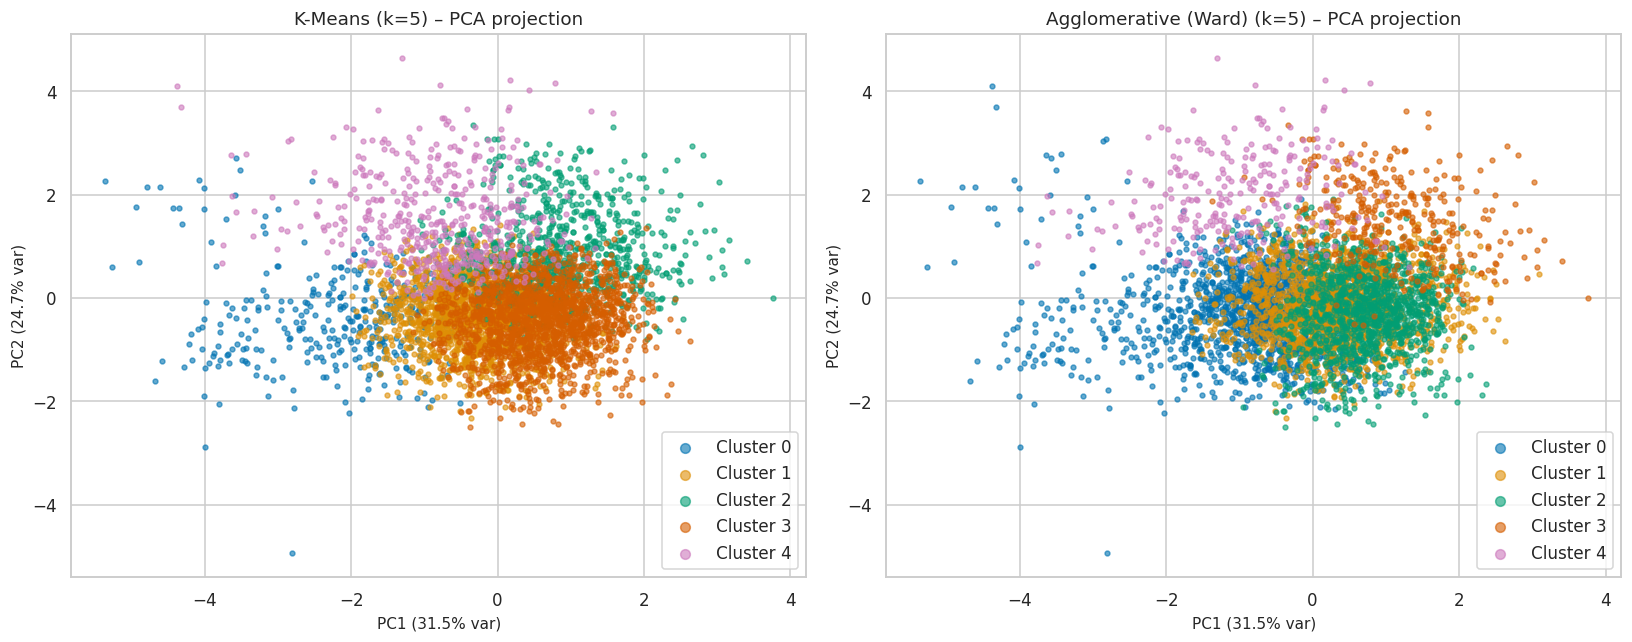

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_scaled)
P = pca.transform(X_s)
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3), '| total:', pca.explained_variance_ratio_.sum().round(3))
display(pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1','PC2']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, lab, name in zip(axes, [kmeans.labels_[idx], agg_labels], ['K-Means', 'Agglomerative (Ward)']):
    for c in range(K):
        ax.scatter(P[lab == c, 0], P[lab == c, 1], s=10, alpha=.6, color=PALETTE[c], label=f'Cluster {c}')
    ax.set_title(f'{name} (k={K}) – PCA projection'); ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)'); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()

**Insight (PCA):** The first two components explain 56.1% of the variance (PC1 31.5%, PC2 24.7%). PC1 is driven by `Approval_Ratio` (+0.65) and `Days_Between_Service_and_Claim` (+0.54) – i.e. *low PC1 = fast, heavily-discounted claims*; PC2 contrasts provider volume (+0.81) with claim size (−0.57). The clusters appear as **overlapping regions of one cloud** rather than isolated islands, consistent with the weak silhouette. Visible structure: K-Means cluster 0 (blue) occupies the far-left (low PC1) edge, cluster 4 (pink) the top (high provider volume) and cluster 2 (green) the upper-right (very small claims). Cluster numbers are arbitrary and differ between the two algorithms.

### 9.2 t-SNE (3,000-claim subset)

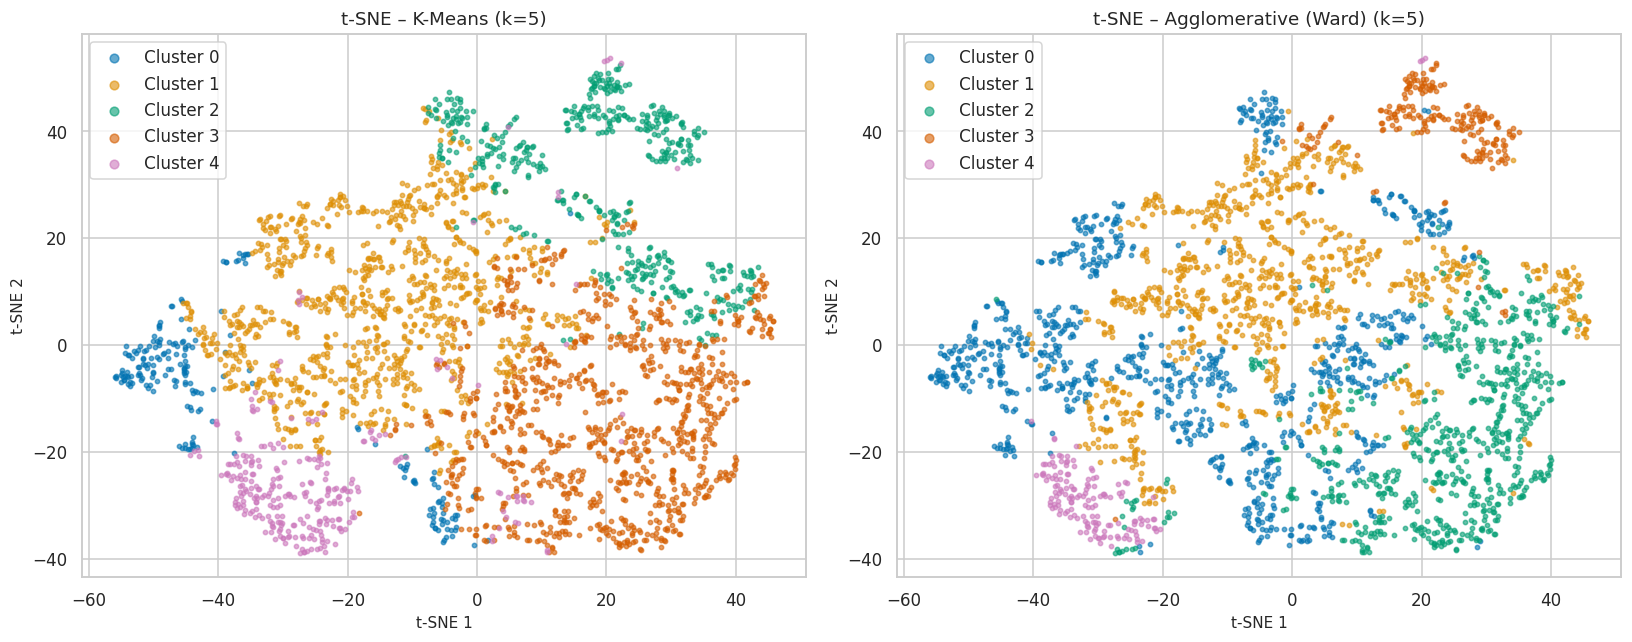

In [ ]:
sub = np.random.RandomState(RANDOM_STATE).choice(SAMPLE_N, 3000, replace=False)   # positions inside the 5k sample
T = TSNE(n_components=2, perplexity=40, init='pca', random_state=RANDOM_STATE).fit_transform(X_s[sub])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, lab, name in zip(axes, [kmeans.labels_[idx][sub], agg_labels[sub]], ['K-Means', 'Agglomerative (Ward)']):
    for c in range(K):
        ax.scatter(T[lab == c, 0], T[lab == c, 1], s=8, alpha=.6, color=PALETTE[c], label=f'Cluster {c}')
    ax.set_title(f't-SNE – {name} (k={K})'); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2'); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()

**Insight (t-SNE):** t-SNE separates local neighbourhoods better than PCA. Under K-Means, cluster 2 (low-value claims) and cluster 4 (high-volume providers) form compact, well-isolated islands, and cluster 0 appears as small tight patches at the outer edge of the map. Clusters 1 and 3 form one continuous sheet that is split by submission delay, which explains the weak overall silhouette. Ward's partition cuts the same sheet differently – visible in the right-hand panel – matching its lower scores. (t-SNE distances between islands are not meaningful; use it for local grouping only.)

## 10. Cluster profiling & post-hoc fraud validation

### 10.1 What defines each K-Means cluster? (original units)

Median of each feature per cluster


,size,Claim_Amount,Approved_Amount,Approval_Ratio,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Patient_Age,Length_of_Stay,Prior_Visits_12m
KMeans_Cluster,,,,,,,,,
0,1480,745.94,424.10,0.62,5.0,68.0,50.0,2.0,3.0
1,6152,591.53,521.97,0.88,8.0,64.0,49.0,2.0,3.0
2,2946,142.45,123.60,0.87,14.0,67.0,49.0,2.0,3.0
3,6314,548.64,475.32,0.87,23.0,64.0,50.0,2.0,3.0
4,1872,580.66,492.74,0.84,14.0,96.0,50.0,2.0,3.0


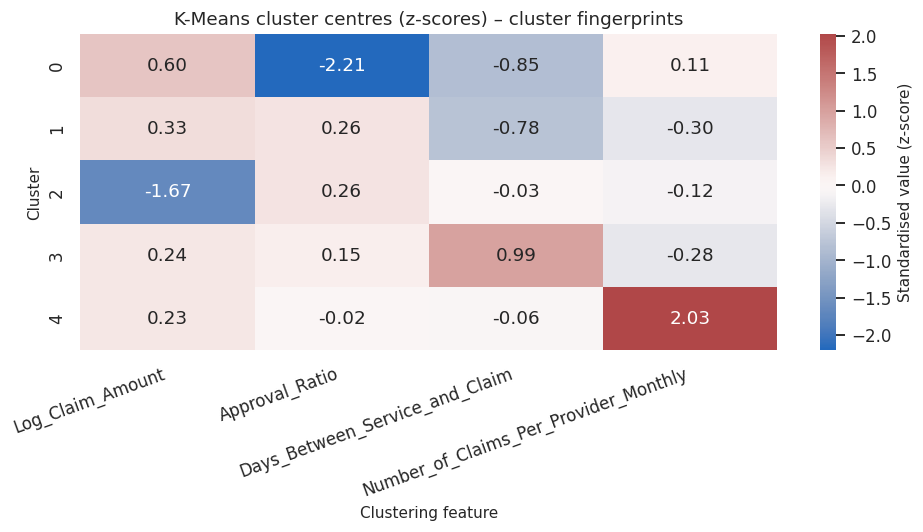

In [ ]:
prof_cols = ['Claim_Amount','Approved_Amount','Approval_Ratio','Days_Between_Service_and_Claim','Number_of_Claims_Per_Provider_Monthly',
             'Patient_Age','Length_of_Stay','Prior_Visits_12m']
profile = df.groupby('KMeans_Cluster')[prof_cols].median().round(2)
profile.insert(0, 'size', df['KMeans_Cluster'].value_counts().sort_index())
print('Median of each feature per cluster'); display(profile)

# z-score heatmap of cluster centres (clustering features only) -> quick visual "fingerprint"
centres = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
plt.figure(figsize=(9, 3.5 + .3*K))
sns.heatmap(centres, annot=True, fmt='.2f', cmap='vlag', center=0, cbar_kws={'label': 'Standardised value (z-score)'})
plt.title('K-Means cluster centres (z-scores) – cluster fingerprints'); plt.ylabel('Cluster'); plt.xlabel('Clustering feature'); plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

**Insight (cluster fingerprints):** The five K-Means clusters have clear, business-readable meanings:

| Cluster | Size | Defining behaviour (medians) | Label |
|---|---|---|---|
| 0 | 7.9% | Filed in **5 days**, only **62%** of the claim approved (claim ≈ 746 → approved ≈ 424) | **Fast-filed, heavily-discounted claims** |
| 1 | 32.8% | Filed in ~8 days (0–16), normal approval ≈ 88% | Prompt standard claims |
| 2 | 15.7% | Very **small claims** (median ≈ 142) | Low-value routine claims |
| 3 | 33.6% | Filed in **~23 days** (15–29), normal approval ≈ 87% | Slow-filed standard claims |
| 4 | 10.0% | Providers with a median of **96 claims/month** (others ≈ 64–68) | High-volume-provider claims |

Age, length of stay and prior visits are identical across clusters (they were excluded from clustering) – confirming they were noise.

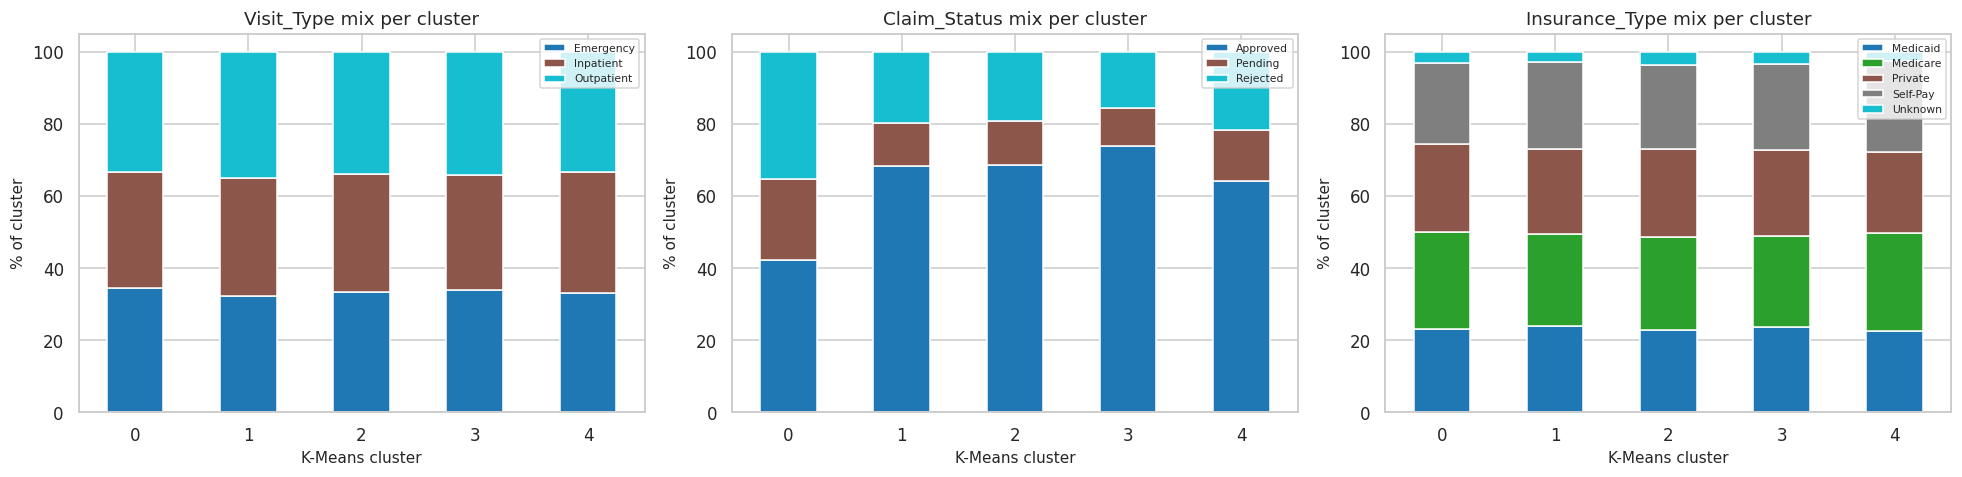

In [ ]:
# Categorical make-up of each cluster (features NOT used for clustering) – % within cluster
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, ['Visit_Type', 'Claim_Status', 'Insurance_Type']):
    (pd.crosstab(df['KMeans_Cluster'], df[c], normalize='index')*100).plot(kind='bar', stacked=True, ax=ax, colormap='tab10', rot=0)
    ax.set_title(f'{c} mix per cluster'); ax.set_xlabel('K-Means cluster'); ax.set_ylabel('% of cluster'); ax.legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()

**Insight (categorical make-up):** Visit type and insurance type are spread evenly across all clusters (≈ ⅓ per visit type, ≈ 25% per insurer), so they do not define any segment. `Claim_Status` does: cluster 0 has only **42% Approved**, 35% Rejected and 22% Pending, versus 64–74% Approved in the other clusters – the insurer's own decisions already treat cluster 0 as suspicious. (Caution: `Approval_Ratio` is decided *after* submission by the insurer, so this reflects insurer behaviour as much as claimant behaviour.)

### 10.2 Post-hoc validation with the fraud label (labels used ONLY here)

,claims,frauds,fraud_rate,lift_vs_base,share_of_all_fraud_%
KMeans_Cluster,,,,,
0,1480,1224,0.827,9.550,75.323
1,6152,201,0.033,0.377,12.369
2,2946,30,0.010,0.118,1.846
3,6314,12,0.002,0.022,0.738
4,1872,158,0.084,0.975,9.723


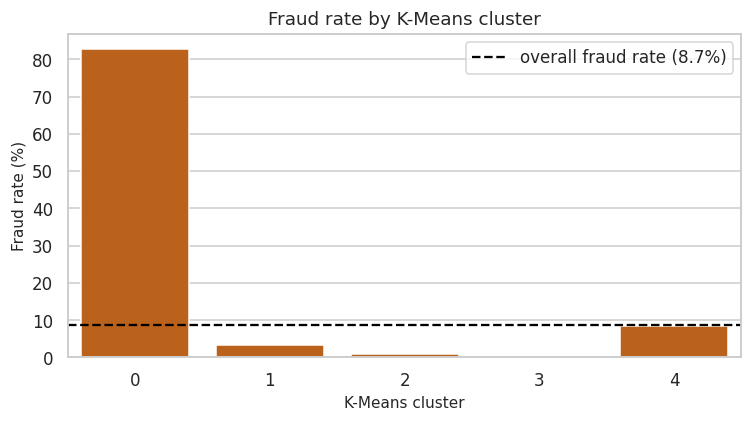

,Adjusted Rand Index,Normalised Mutual Info,Homogeneity
K-Means (all claims),0.092,0.193,0.572
Agglomerative (5k sample),0.013,0.104,0.307


Highest-risk cluster = 0: precision (fraud rate) 82.7%, recall (share of all fraud captured) 75.3%, size 7.9% of claims

Agglomerative fraud rate per cluster (5k sample):


,claims,fraud_rate
Agglo_Cluster,,
0,1567,0.244
1,1625,0.000
2,1186,0.001
3,362,0.011
4,260,0.131


In [ ]:
base = df['Is_Fraud'].mean()
val = df.groupby('KMeans_Cluster')['Is_Fraud'].agg(claims='size', frauds='sum', fraud_rate='mean')
val['lift_vs_base'] = val['fraud_rate'] / base
val['share_of_all_fraud_%'] = val['frauds'] / val['frauds'].sum() * 100
display(val.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=val.index, y=val['fraud_rate']*100, color=PALETTE[3], ax=ax)
ax.axhline(base*100, ls='--', color='black', label=f'overall fraud rate ({base:.1%})')
ax.set_title('Fraud rate by K-Means cluster'); ax.set_xlabel('K-Means cluster'); ax.set_ylabel('Fraud rate (%)'); ax.legend(); plt.tight_layout(); plt.show()

ext = pd.DataFrame({
  'K-Means (all claims)': [adjusted_rand_score(df.Is_Fraud, df.KMeans_Cluster), normalized_mutual_info_score(df.Is_Fraud, df.KMeans_Cluster), homogeneity_score(df.Is_Fraud, df.KMeans_Cluster)],
  'Agglomerative (5k sample)': [adjusted_rand_score(df_s.Is_Fraud, df_s.Agglo_Cluster), normalized_mutual_info_score(df_s.Is_Fraud, df_s.Agglo_Cluster), homogeneity_score(df_s.Is_Fraud, df_s.Agglo_Cluster)]},
  index=['Adjusted Rand Index', 'Normalised Mutual Info', 'Homogeneity']).T
display(ext.round(3))

top = val['fraud_rate'].idxmax(); in_top = df['KMeans_Cluster'] == top
print(f'Highest-risk cluster = {top}: precision (fraud rate) {df.loc[in_top,"Is_Fraud"].mean():.1%}, recall (share of all fraud captured) {df.loc[in_top,"Is_Fraud"].sum()/df.Is_Fraud.sum():.1%}, size {in_top.mean():.1%} of claims')
print('\nAgglomerative fraud rate per cluster (5k sample):'); display(df_s.groupby('Agglo_Cluster')['Is_Fraud'].agg(claims='size', fraud_rate='mean').round(3))

**Insight (fraud validation, labels used only now):** K-Means cluster 0 contains **82.7% fraud (9.6× the base rate)** and captures **75.3% of all fraud while holding only 7.9% of claims**. Clusters 2 and 3 are almost fraud-free (≤ 1%). The unsupervised model therefore *rediscovered* the fraud signal (fast filing + low approval ratio) without ever seeing a label. Global agreement scores are modest (ARI 0.09, NMI 0.19) because the remaining ≈ 25% of fraud looks like normal claims (≈ 201 in cluster 1, 158 in cluster 4) and cannot be separated by these four features – clustering is a screening tool, not a classifier. K-Means is also clearly more fraud-homogeneous (0.57) than Ward (0.31); Ward's cluster 0 mixes in 24% fraud.

## 11. Stability check

In [ ]:
seeds = range(10); ref = kmeans.labels_; rows = []
for sd in seeds:
    lab = KMeans(K, n_init=10, random_state=sd).fit_predict(X_scaled)
    rows.append({'seed': sd, 'silhouette': silhouette_score(X_scaled, lab, sample_size=5000, random_state=RANDOM_STATE), 'ARI vs final model': adjusted_rand_score(ref, lab)})
stab = pd.DataFrame(rows).set_index('seed'); display(stab.round(3)); print(stab.agg(['mean','std','min']).round(3))

,silhouette,ARI vs final model
seed,,
0,0.233,0.997
1,0.233,0.998
2,0.233,0.997
3,0.233,0.999
4,0.233,0.997
5,0.233,0.996
6,0.233,0.998
7,0.233,0.996
8,0.233,0.997


      silhouette  ARI vs final model
mean       0.233               0.997
std        0.000               0.001
min        0.233               0.996


**Insight (stability):** Across 10 different random seeds the K-Means partition is almost identical to the final one (mean ARI = 0.997, minimum 0.996) and the silhouette is constant at 0.233. The clusters are therefore **reproducible**, not artefacts of random initialisation.

## 12. Save outputs

In [ ]:
import joblib
Path('models').mkdir(exist_ok=True)
joblib.dump({'scaler': scaler, 'kmeans': kmeans, 'features': FEATURES}, 'models/kmeans_claims.pkl')
final = pd.concat([cmp.round(4)])
final.to_csv('clustering_results_summary.csv'); display(final)

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
K-Means (k=5) – 5k sample,0.2329,1.2375,1263.0431
Agglomerative Ward (k=5) – 5k sample,0.1663,1.4327,938.4680
"K-Means (k=5) – all 18,764 claims",0.2329,1.2478,4698.9513


## Conclusions

**The dataset is partially good for clustering.** It is workable but not ideal. The numeric features are nearly uncorrelated (simulated data), so the natural cluster structure is weak (best silhouette 0.23). Careful feature selection (4 of 7 features, silhouette ×2) and a log transform were essential to extract any structure.

**Findings**
1. **k = 5** is supported by silhouette, Davies-Bouldin and Calinski-Harabasz simultaneously, and by the dendrogram cut.
2. **K-Means outperforms Ward hierarchical clustering** on all three internal metrics and is highly stable across seeds (ARI 0.997). Single/average/complete linkage degenerate into 1–2-point clusters.
3. The five segments are interpretable: fast-filed/discounted, prompt standard, low-value, slow-filed standard and high-volume-provider claims.
4. The **fast-filed, heavily-discounted** segment (7.9% of claims) holds 75% of all fraud at an 82.7% fraud rate – a useful risk-screening group found *without labels*.

**Limitations**
- Weak separation (silhouette 0.23); clusters overlap in PCA space.
- Synthetic-looking data (uncorrelated features, outpatients with hospital stays, approved > claimed in 968 rows).
- Hierarchical clustering was run on a 5,000-claim random sample (an n×n distance matrix for all 18,764 claims needs ≈ 2.8 GB).
- `Approval_Ratio` is an insurer decision, so part of the fraud signal reflects the review process itself.
- Internal metrics cannot prove that clusters are "true" groups – the fraud validation is the external check.

**Possible extensions:** Gaussian Mixture Models for soft assignments, DBSCAN for noise detection, and a Streamlit app that assigns a new claim to a segment (bonus marks).